# Сравнение независимых экспериментов LFPG, EGLL и EDDF

Каждая модель обучена отдельно для своего аэропорта. Зафиксированы исходные сезонные дни 1.1: девять train, три validation и три test. Горизонт 27–33 секунды, поправка к физическому baseline, равный вклад заходов. Перенос обученной модели между аэропортами здесь не исследуется

,model,macro_mae_ft,macro_rmse_ft,run_id,airport
0,Constant vertical rate,49.348959,67.995818,af81171321ba41da902589bff85a3858,LFPG
1,Ridge,20.033286,25.796078,58f9e5e9015e4478b4c9631b4aa613d0,LFPG
2,Polynomial Ridge,17.163963,22.244615,54224c6909c1451aa7c24c45feaa2dc5,LFPG
3,PyTorch MLP,18.862559,24.466738,e1e47564e32845768281b8f447e7e21b,LFPG
4,Constant vertical rate,55.953272,81.923198,77511f5022e34b5caf1c988466047793,EGLL
5,Ridge,16.337442,24.521356,019df70260ad45ec9299b2efc60829cc,EGLL
6,Polynomial Ridge,15.448957,24.743112,a1836409248444b0ae6250bd2a1aa52c,EGLL
7,PyTorch MLP,14.516123,20.314007,7432f453bb1e46e0924dc4ae5bfb212a,EGLL
8,Constant vertical rate,72.603506,117.367842,ab3f157c9a354866bb3673c2dd4f4138,EDDF
9,Ridge,22.225478,32.310559,586f82fc484d45c69e23761575b0b58b,EDDF


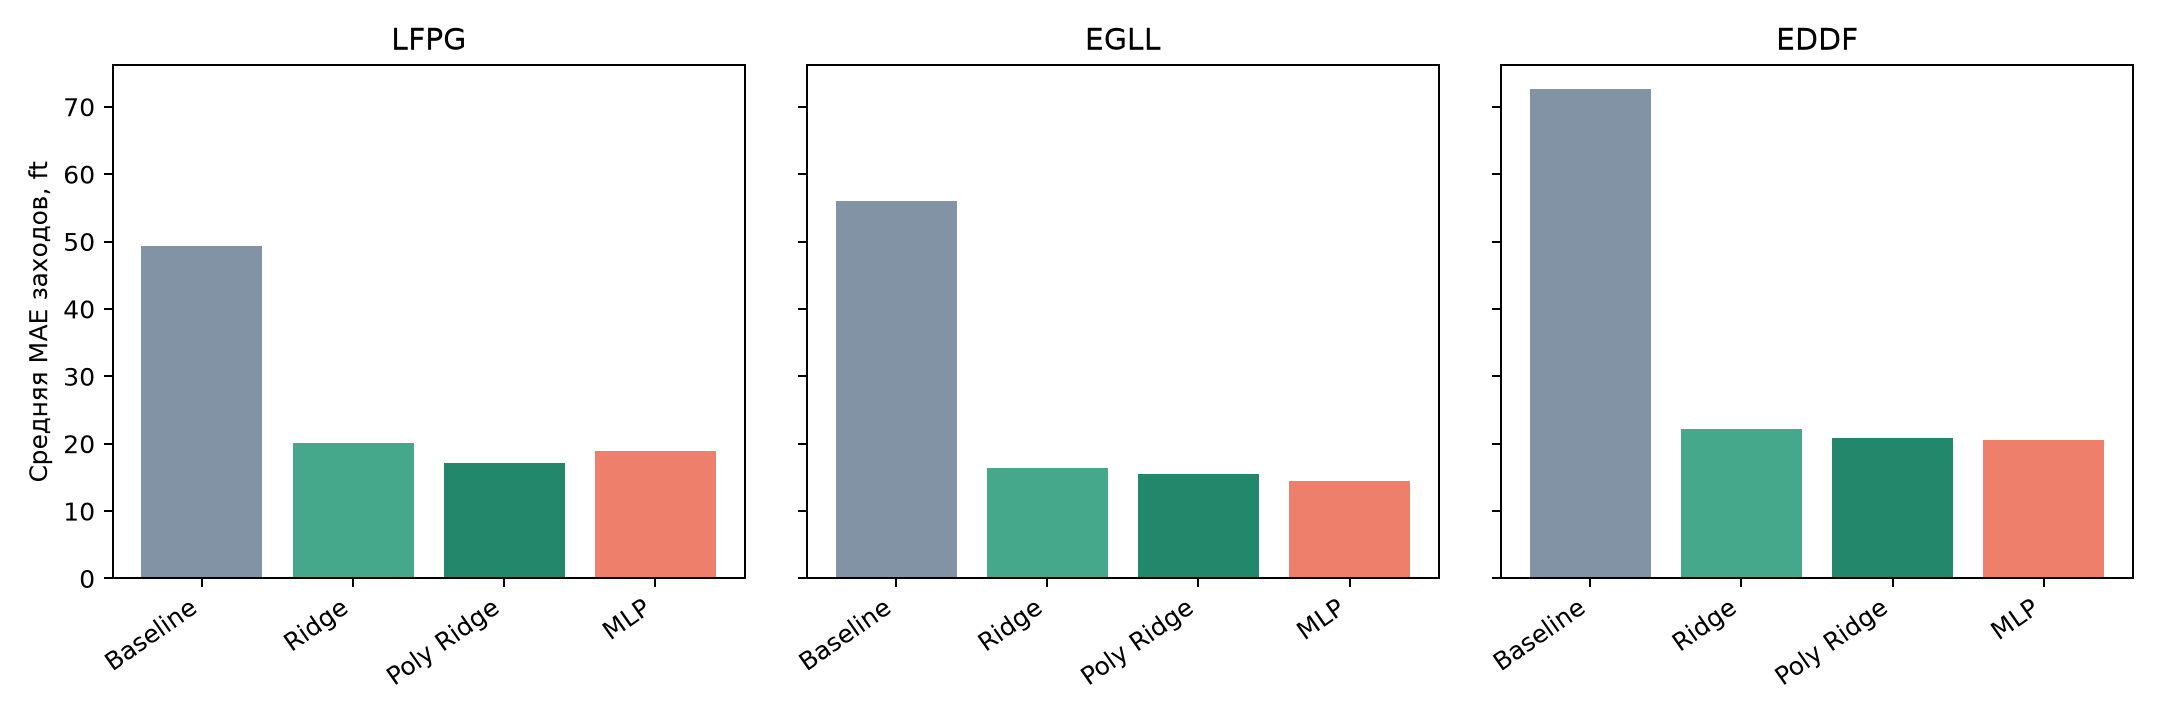

In [1]:
# Загружаем сохраненные результаты без повторного обучения
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root / "reports/three_airports_metrics.csv"))
display(Image(filename=str(root / "reports/three_airports_comparison.png")))

## EGLL: выборка, загрузка и выбор модели

Данные проходят те же проверки причинности и согласованности. Дополнительное поле airport_elevation_ft сохранено в PostgreSQL как метаданные. Повторная загрузка не добавляет строк. Все модели этого аэропорта оценены на одинаковом test. Классические MAE сверены с 1.1

,season,split,rows,events
0,autumn,test,13472,367
1,autumn,train,39770,1146
2,autumn,validation,12151,362
3,spring,test,7014,385
4,spring,train,19537,1136
5,spring,validation,6457,388
6,summer,test,15224,384
7,summer,train,41384,1156
8,summer,validation,11499,277


{'read': 166508, 'inserted': 0, 'already_present': 166508, 'database_rows': 166508, 'extracted': 166508, 'roundtrip_exact': True}


,model,parameter,validation_macro_mae_ft
0,Ridge,1,16.183624
1,Ridge,10,16.168880
2,Ridge,100,16.244204
3,Polynomial Ridge,1,15.751428
4,Polynomial Ridge,10,15.729394
5,Polynomial Ridge,100,15.972120
6,PyTorch MLP,16,15.023992
7,PyTorch MLP,32,14.886854


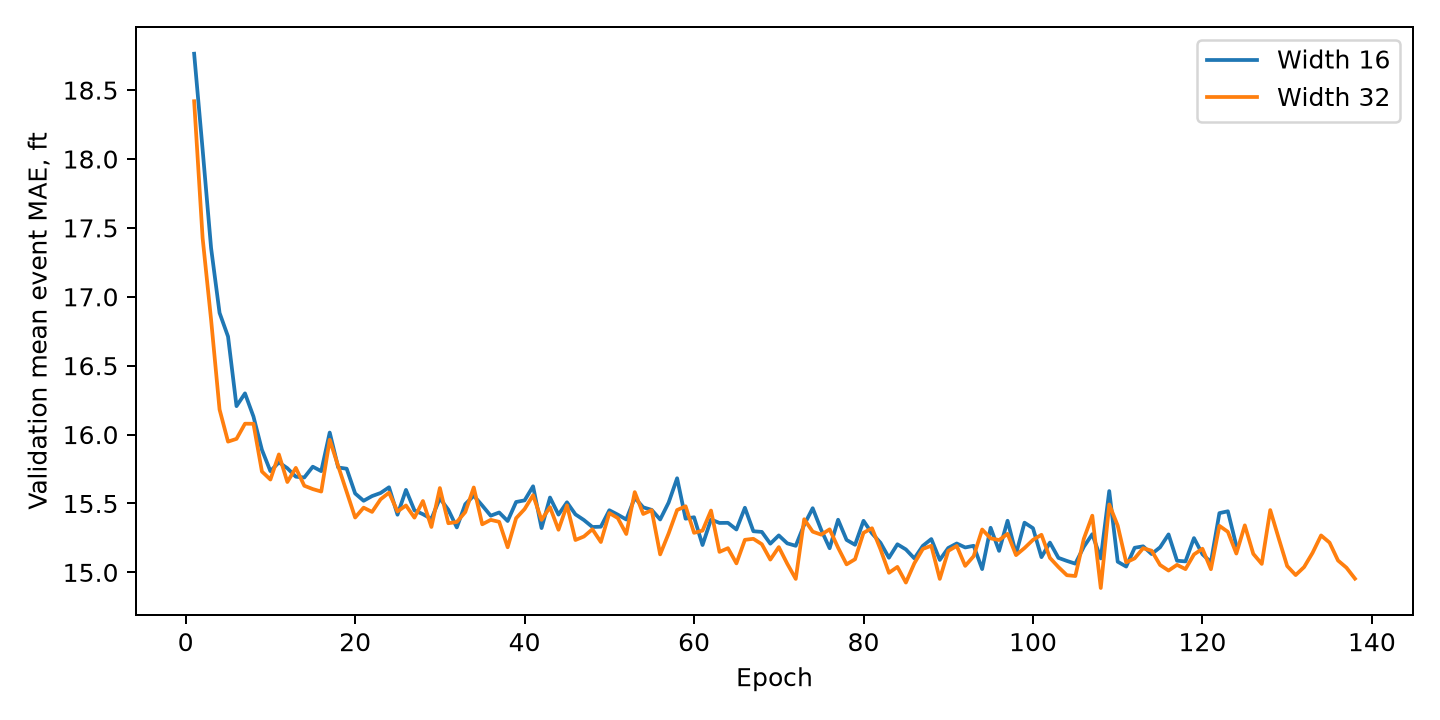

In [2]:
# Показываем инвентаризацию, проверку импорта и выбор по validation
display(pd.read_csv(root / "reports/EGLL/split_inventory.csv"))
print(json.loads((root / "reports/EGLL/ingestion.json").read_text()))
display(pd.read_csv(root / "reports/EGLL/validation_search.csv"))
display(Image(filename=str(root / "reports/EGLL/mlp_validation.png")))

## EGLL: парный анализ ошибок и неопределенности

Все сравнения выполнены на сохраненных моделях без переобучения. MAE, bias и MSE сначала усредняются внутри захода. Bias = прогноз минус наблюдение; положительный знак означает завышение высоты. P90 – 90-й процентиль MAE заходов. Сезон здесь представлен одним днем и не отделен от состава этого дня

Парный bootstrap выбирает борта с возвращением, сохраняя все заходы выбранного борта вместе. 10 000 повторов, seed 20261014, границы 2.5% и 97.5%. Интервалы условны на трех наблюдаемых днях: общая зависимость внутри дня и неопределенность обучения не моделируются. Один seed MLP, без поправки на множественные сравнения; анализ выполнен после просмотра test

,model,day,season,events,macro_mae_ft,macro_bias_ft,macro_rmse_ft,p90_event_mae_ft
0,Constant vertical rate,2025-04-07,spring,385,59.702257,-13.988528,84.084056,93.694958
1,Constant vertical rate,2025-08-25,summer,384,66.056653,-18.077972,95.645796,100.246061
2,Constant vertical rate,2025-10-18,autumn,367,41.449029,-9.467566,61.526567,62.366594
3,Polynomial Ridge,2025-04-07,spring,385,16.672512,-2.452245,31.106240,24.306193
4,Polynomial Ridge,2025-08-25,summer,384,16.203853,0.853835,23.113602,23.574887
5,Polynomial Ridge,2025-10-18,autumn,367,13.375528,-2.220266,17.916762,19.743265
6,PyTorch MLP,2025-04-07,spring,385,14.968176,-3.522923,21.164497,23.662292
7,PyTorch MLP,2025-08-25,summer,384,15.771899,-0.618000,22.237188,22.151509
8,PyTorch MLP,2025-10-18,autumn,367,12.727952,-3.708510,17.030188,18.903195
9,Ridge,2025-04-07,spring,385,17.587273,-4.666921,28.673385,25.220680


,model,reference,events,aircraft,mean_delta_mae_ft,lower_95_ft,upper_95_ft,better_events,worse_events,tied_events
0,Polynomial Ridge,Constant vertical rate,1136,642,-40.504315,-42.012510,-39.050932,1134,2,0
1,PyTorch MLP,Constant vertical rate,1136,642,-41.437150,-42.929809,-39.976214,1135,1,0
2,PyTorch MLP,Polynomial Ridge,1136,642,-0.932835,-1.134231,-0.767711,777,359,0
3,Ridge,Polynomial Ridge,1136,642,0.888485,0.758023,1.025196,321,815,0


,day,model,reference,events,mean_delta_mae_ft,better_events
6,2025-04-07,PyTorch MLP,Polynomial Ridge,385,-1.704336,312
7,2025-08-25,PyTorch MLP,Polynomial Ridge,384,-0.431954,212
8,2025-10-18,PyTorch MLP,Polynomial Ridge,367,-0.647576,253


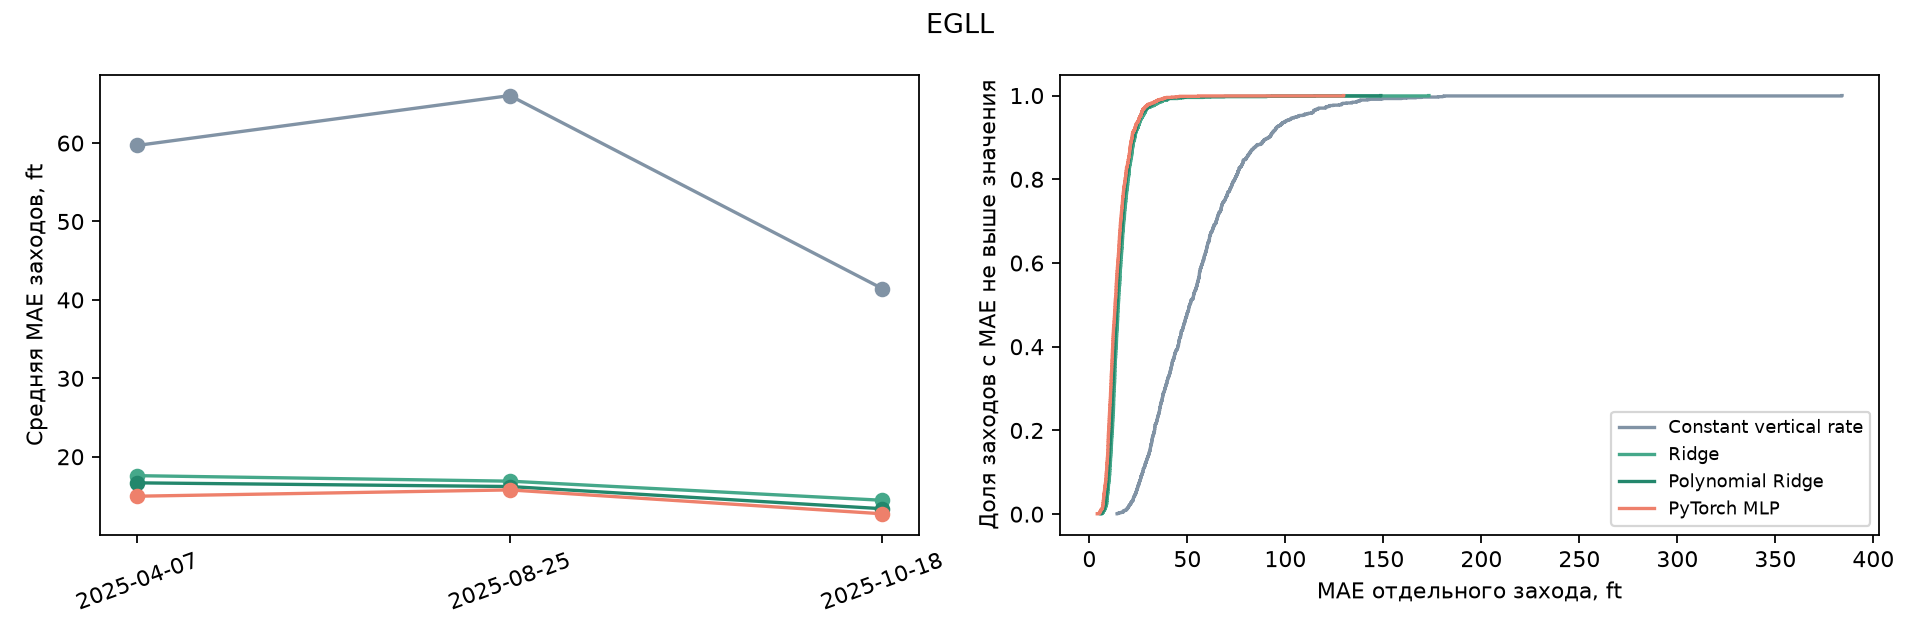

In [3]:
# Показываем ошибки по дням, парные разницы и интервалы
display(pd.read_csv(root / "reports/EGLL/errors_by_day.csv"))
display(pd.read_csv(root / "reports/EGLL/paired_uncertainty.csv"))
daily = pd.read_csv(root / "reports/EGLL/paired_errors_by_day.csv")
display(daily.loc[daily.model.eq("PyTorch MLP") & daily.reference.eq("Polynomial Ridge")])
display(Image(filename=str(root / "reports/EGLL/error_analysis.png")))

MLP улучшила Polynomial Ridge на 777 из 1136 заходов; средняя разница −0.93 ft, условный интервал −1.13…−0.77 ft. Средние разницы на всех трех днях отрицательны: −1.70, −0.43, −0.65 ft. MLP в среднем занижает высоту на каждом из этих дней. Вывод ограничен выбранной выборкой и не подтверждает перенос на другие условия

## EDDF: выборка, загрузка и выбор модели

Данные проходят те же проверки причинности и согласованности. Дополнительное поле airport_elevation_ft сохранено в PostgreSQL как метаданные. Повторная загрузка не добавляет строк. Все модели этого аэропорта оценены на одинаковом test. Классические MAE сверены с 1.1

,season,split,rows,events
0,autumn,test,5919,172
1,autumn,train,21967,566
2,autumn,validation,6807,189
3,spring,test,6595,206
4,spring,train,9246,458
5,spring,validation,3759,177
6,summer,test,6823,162
7,summer,train,29215,533
8,summer,validation,6383,171


{'read': 96714, 'inserted': 0, 'already_present': 96714, 'database_rows': 96714, 'extracted': 96714, 'roundtrip_exact': True}


,model,parameter,validation_macro_mae_ft
0,Ridge,1,22.398563
1,Ridge,10,22.367554
2,Ridge,100,22.354038
3,Polynomial Ridge,1,21.080186
4,Polynomial Ridge,10,21.125482
5,Polynomial Ridge,100,21.635613
6,PyTorch MLP,16,20.682799
7,PyTorch MLP,32,20.528188


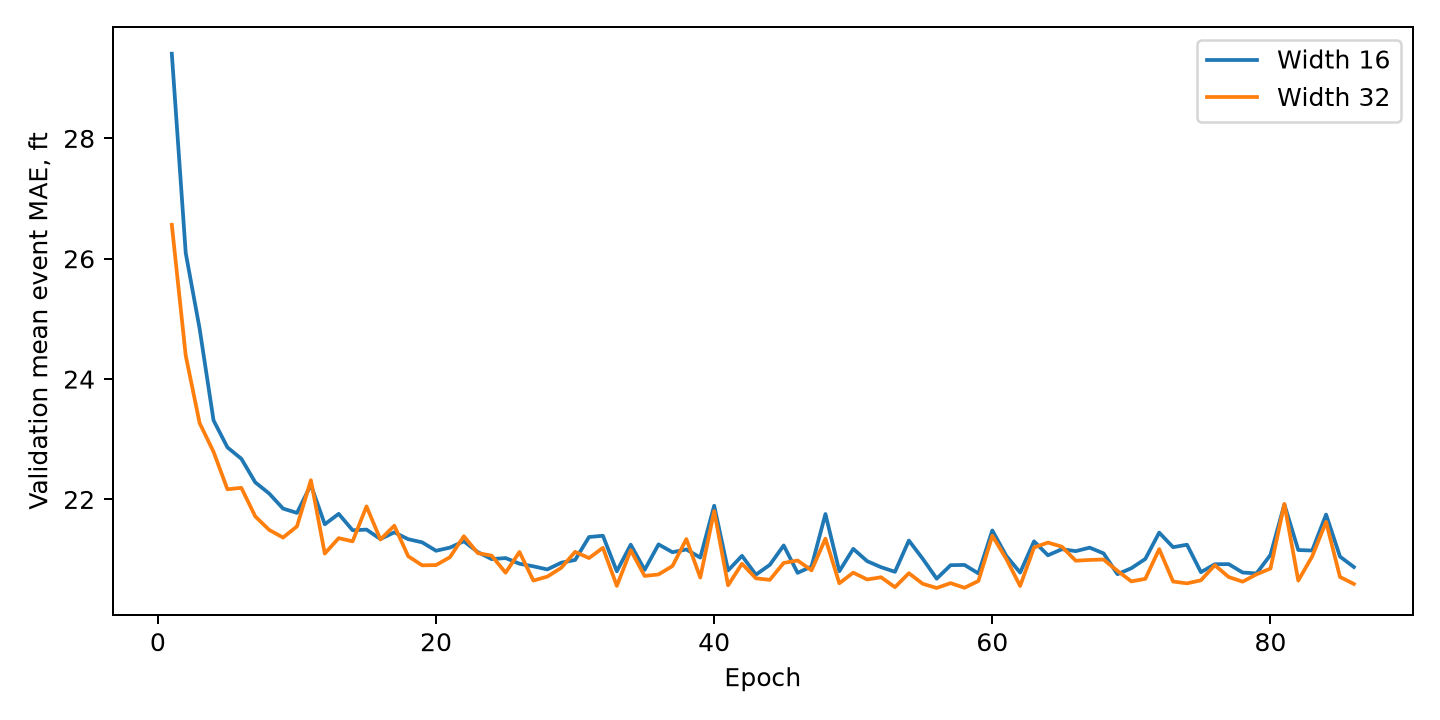

In [4]:
# Показываем инвентаризацию, проверку импорта и выбор по validation
display(pd.read_csv(root / "reports/EDDF/split_inventory.csv"))
print(json.loads((root / "reports/EDDF/ingestion.json").read_text()))
display(pd.read_csv(root / "reports/EDDF/validation_search.csv"))
display(Image(filename=str(root / "reports/EDDF/mlp_validation.png")))

## EDDF: парный анализ ошибок и неопределенности

Все сравнения выполнены на сохраненных моделях без переобучения. MAE, bias и MSE сначала усредняются внутри захода. Bias = прогноз минус наблюдение; положительный знак означает завышение высоты. P90 – 90-й процентиль MAE заходов. Сезон здесь представлен одним днем и не отделен от состава этого дня

Парный bootstrap выбирает борта с возвращением, сохраняя все заходы выбранного борта вместе. 10 000 повторов, seed 20261014, границы 2.5% и 97.5%. Интервалы условны на трех наблюдаемых днях: общая зависимость внутри дня и неопределенность обучения не моделируются. Один seed MLP, без поправки на множественные сравнения; анализ выполнен после просмотра test

,model,day,season,events,macro_mae_ft,macro_bias_ft,macro_rmse_ft,p90_event_mae_ft
0,Constant vertical rate,2025-05-09,spring,206,79.561519,-21.200500,112.238645,113.038573
1,Constant vertical rate,2025-08-18,summer,162,67.332208,-13.996006,114.538443,91.157946
2,Constant vertical rate,2025-10-19,autumn,172,69.234900,-24.028694,125.712825,116.296307
3,Polynomial Ridge,2025-05-09,spring,206,24.253531,-0.788213,34.085770,37.339892
4,Polynomial Ridge,2025-08-18,summer,162,17.809355,-0.223834,23.995827,27.415265
5,Polynomial Ridge,2025-10-19,autumn,172,19.711146,0.666544,29.232452,32.921724
6,PyTorch MLP,2025-05-09,spring,206,22.848985,1.724951,31.911291,33.081289
7,PyTorch MLP,2025-08-18,summer,162,18.166758,2.408096,24.406513,26.693684
8,PyTorch MLP,2025-10-19,autumn,172,20.080909,1.070359,29.507719,33.679368
9,Ridge,2025-05-09,spring,206,25.588231,-3.851437,36.676141,37.775396


,model,reference,events,aircraft,mean_delta_mae_ft,lower_95_ft,upper_95_ft,better_events,worse_events,tied_events
0,Polynomial Ridge,Constant vertical rate,540,302,-51.730062,-56.285218,-47.666414,540,0,0
1,PyTorch MLP,Constant vertical rate,540,302,-52.040873,-56.688870,-47.868562,540,0,0
2,PyTorch MLP,Polynomial Ridge,540,302,-0.310811,-0.563259,-0.055395,294,246,0
3,Ridge,Polynomial Ridge,540,302,1.352033,1.011691,1.739186,168,372,0


,day,model,reference,events,mean_delta_mae_ft,better_events
6,2025-05-09,PyTorch MLP,Polynomial Ridge,206,-1.404547,148
7,2025-08-18,PyTorch MLP,Polynomial Ridge,162,0.357403,78
8,2025-10-19,PyTorch MLP,Polynomial Ridge,172,0.369763,68


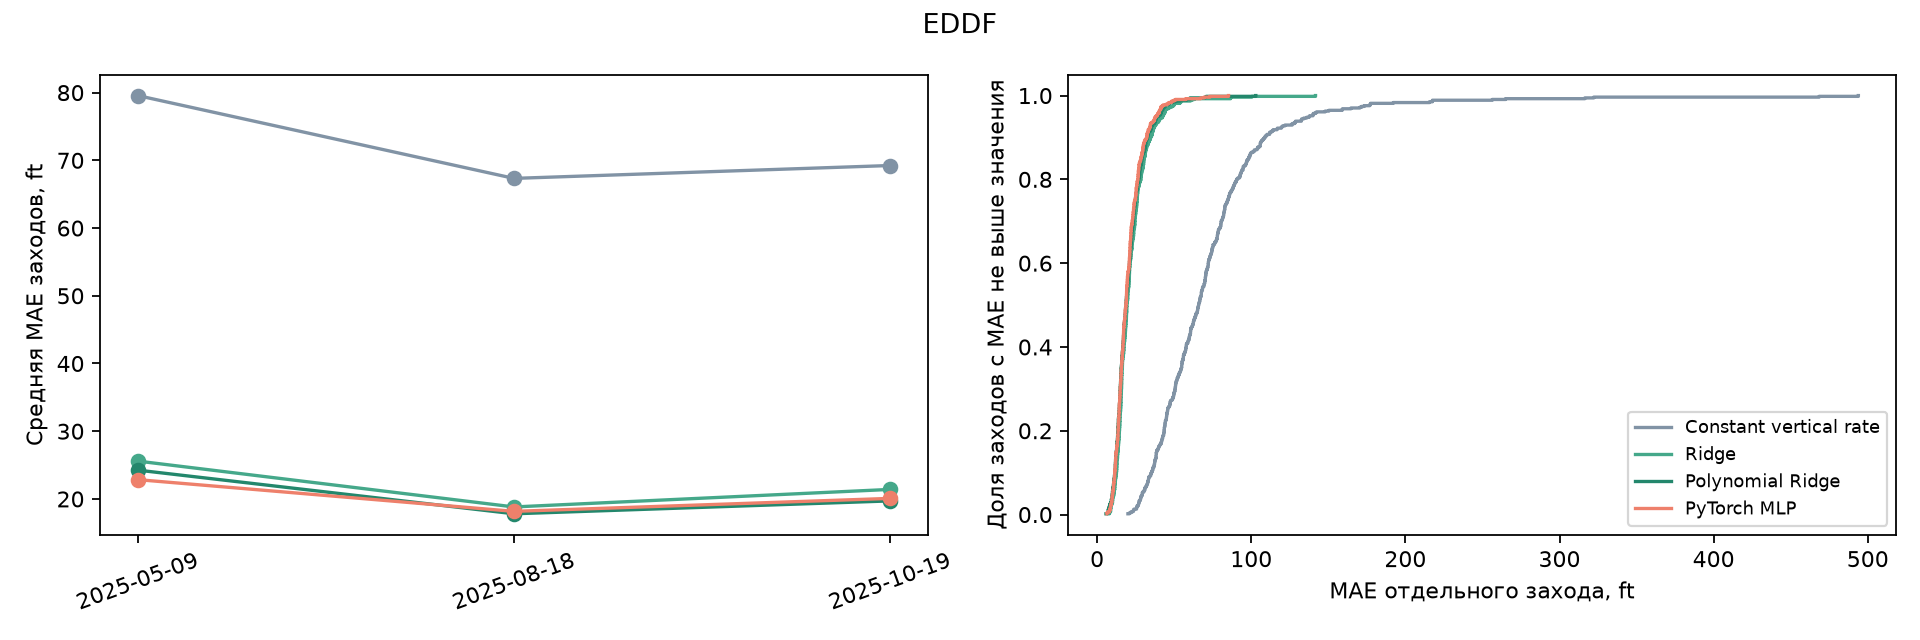

In [5]:
# Показываем ошибки по дням, парные разницы и интервалы
display(pd.read_csv(root / "reports/EDDF/errors_by_day.csv"))
display(pd.read_csv(root / "reports/EDDF/paired_uncertainty.csv"))
daily = pd.read_csv(root / "reports/EDDF/paired_errors_by_day.csv")
display(daily.loc[daily.model.eq("PyTorch MLP") & daily.reference.eq("Polynomial Ridge")])
display(Image(filename=str(root / "reports/EDDF/error_analysis.png")))

MLP улучшила Polynomial Ridge на 294 из 540 заходов; средняя разница −0.31 ft, условный интервал −0.56…−0.06 ft. По дням знак меняется: май −1.40 ft, август +0.36 ft, октябрь +0.37 ft. Общий выигрыш определяется майским днем; преимущество не сохраняется во всех тестовых днях. MLP в среднем завышает высоту на всех трех днях. Интервал по бортам не устраняет зависимость результата от конкретного дня

## Ошибки по высоте и удалению до порога

Использованы сохраненные модели и заранее заданные для этой описательной диагностики интервалы. MAE сначала усредняется внутри захода и интервала, затем между представленными заходами. Один заход может присутствовать в нескольких интервалах; состав выборки меняется. Средние по интервалам нельзя складывать для восстановления общей MAE. Высота является барометрическим прокси, а не радиовысотой. Границы не являются эксплуатационными ограничениями

,airport,feature,bin,model,events,pairs,macro_mae_ft,macro_bias_ft
0,LFPG,height_ft,500–1000,Constant vertical rate,50,383,38.781170,-11.922694
1,LFPG,height_ft,1000–1500,Constant vertical rate,54,766,53.856805,-25.739893
2,LFPG,height_ft,1500–2000,Constant vertical rate,55,435,48.704156,-16.704833
3,LFPG,height_ft,2000–3000,Constant vertical rate,55,340,53.598630,-16.092150
4,LFPG,height_ft,500–1000,Ridge,50,383,14.558485,5.918776
...,...,...,...,...,...,...,...,...
111,EDDF,distance_m,2–4,PyTorch MLP,417,1895,11.229017,-2.548549
112,EDDF,distance_m,4–6,PyTorch MLP,540,4328,14.140813,-1.624923
113,EDDF,distance_m,6–8,PyTorch MLP,540,3323,17.915205,2.448051
114,EDDF,distance_m,8–12,PyTorch MLP,540,6288,24.282963,3.515581


,airport,feature,bin,events,delta_mae_ft,better_events,worse_events
0,LFPG,height_ft,500–1000,50,1.076226,20,30
1,LFPG,height_ft,1000–1500,54,0.607199,21,33
2,LFPG,height_ft,1500–2000,55,-0.594008,29,26
3,LFPG,height_ft,2000–3000,55,3.637606,15,40
4,LFPG,distance_m,2–4,15,2.530964,3,12
5,LFPG,distance_m,4–6,52,0.397301,24,28
6,LFPG,distance_m,6–8,54,0.553877,23,31
7,LFPG,distance_m,8–12,55,0.480946,22,33
8,LFPG,distance_m,≥12,55,3.830881,14,41
9,EGLL,height_ft,500–1000,1106,-0.970630,650,456


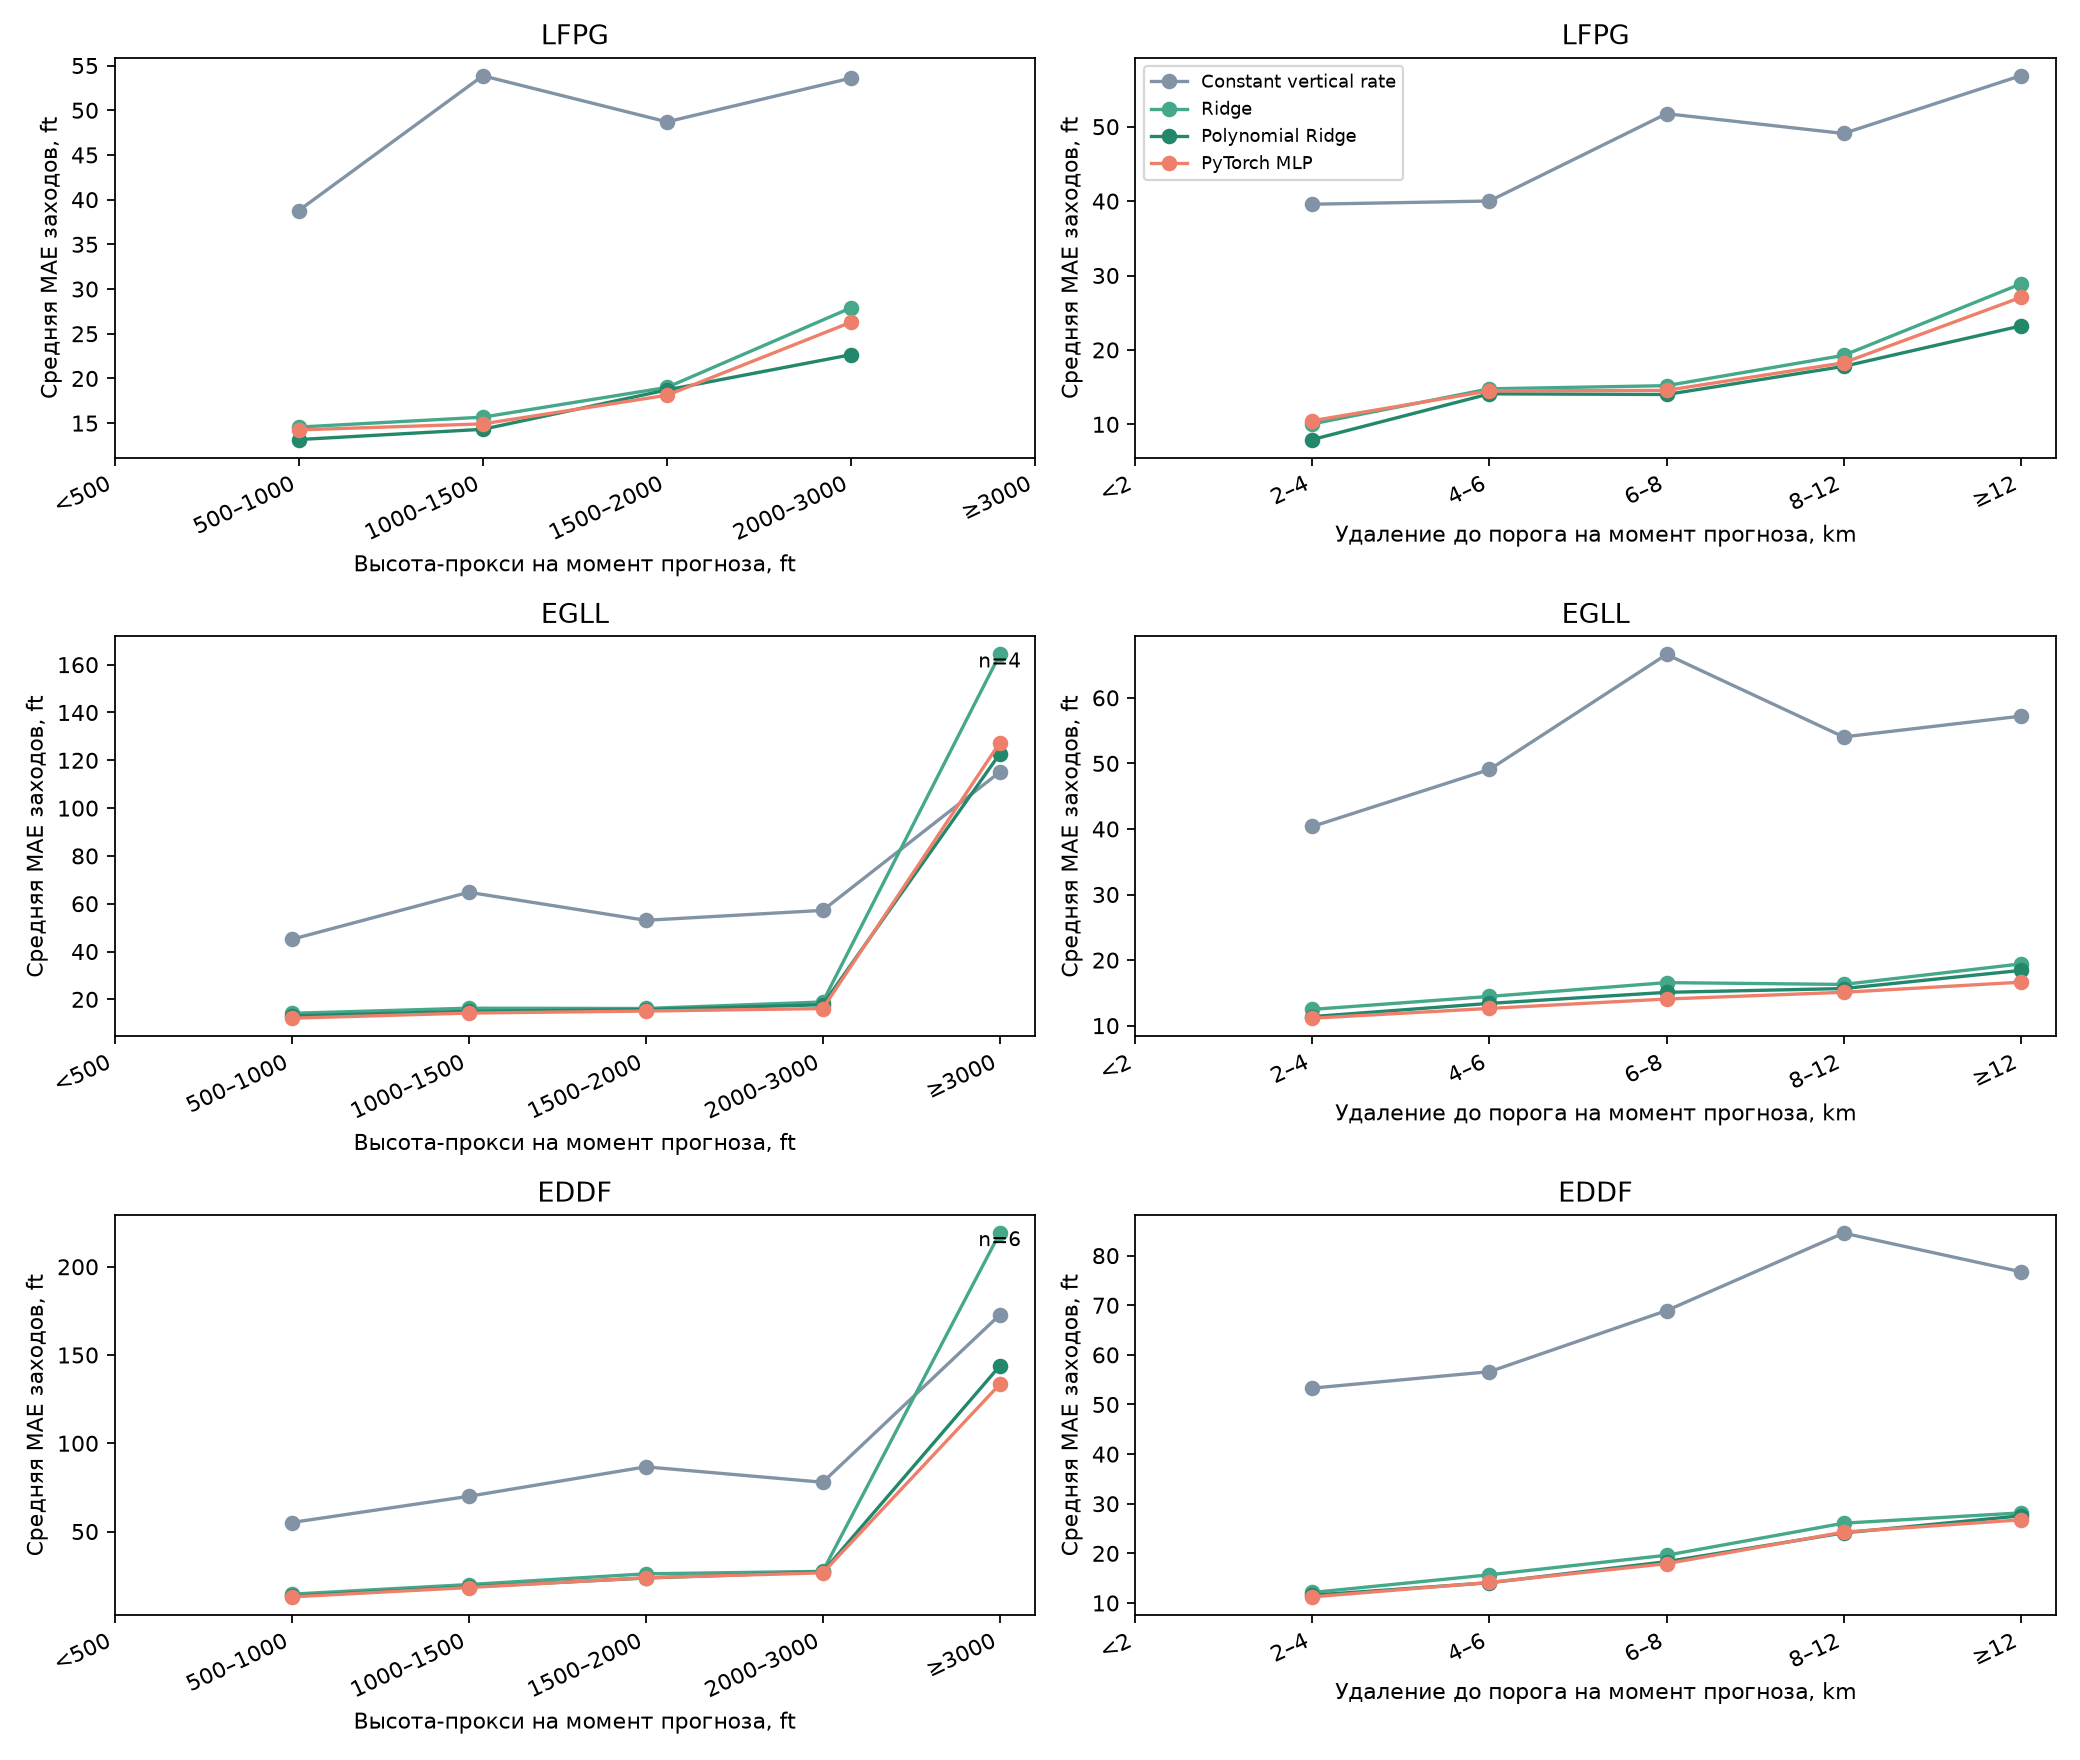

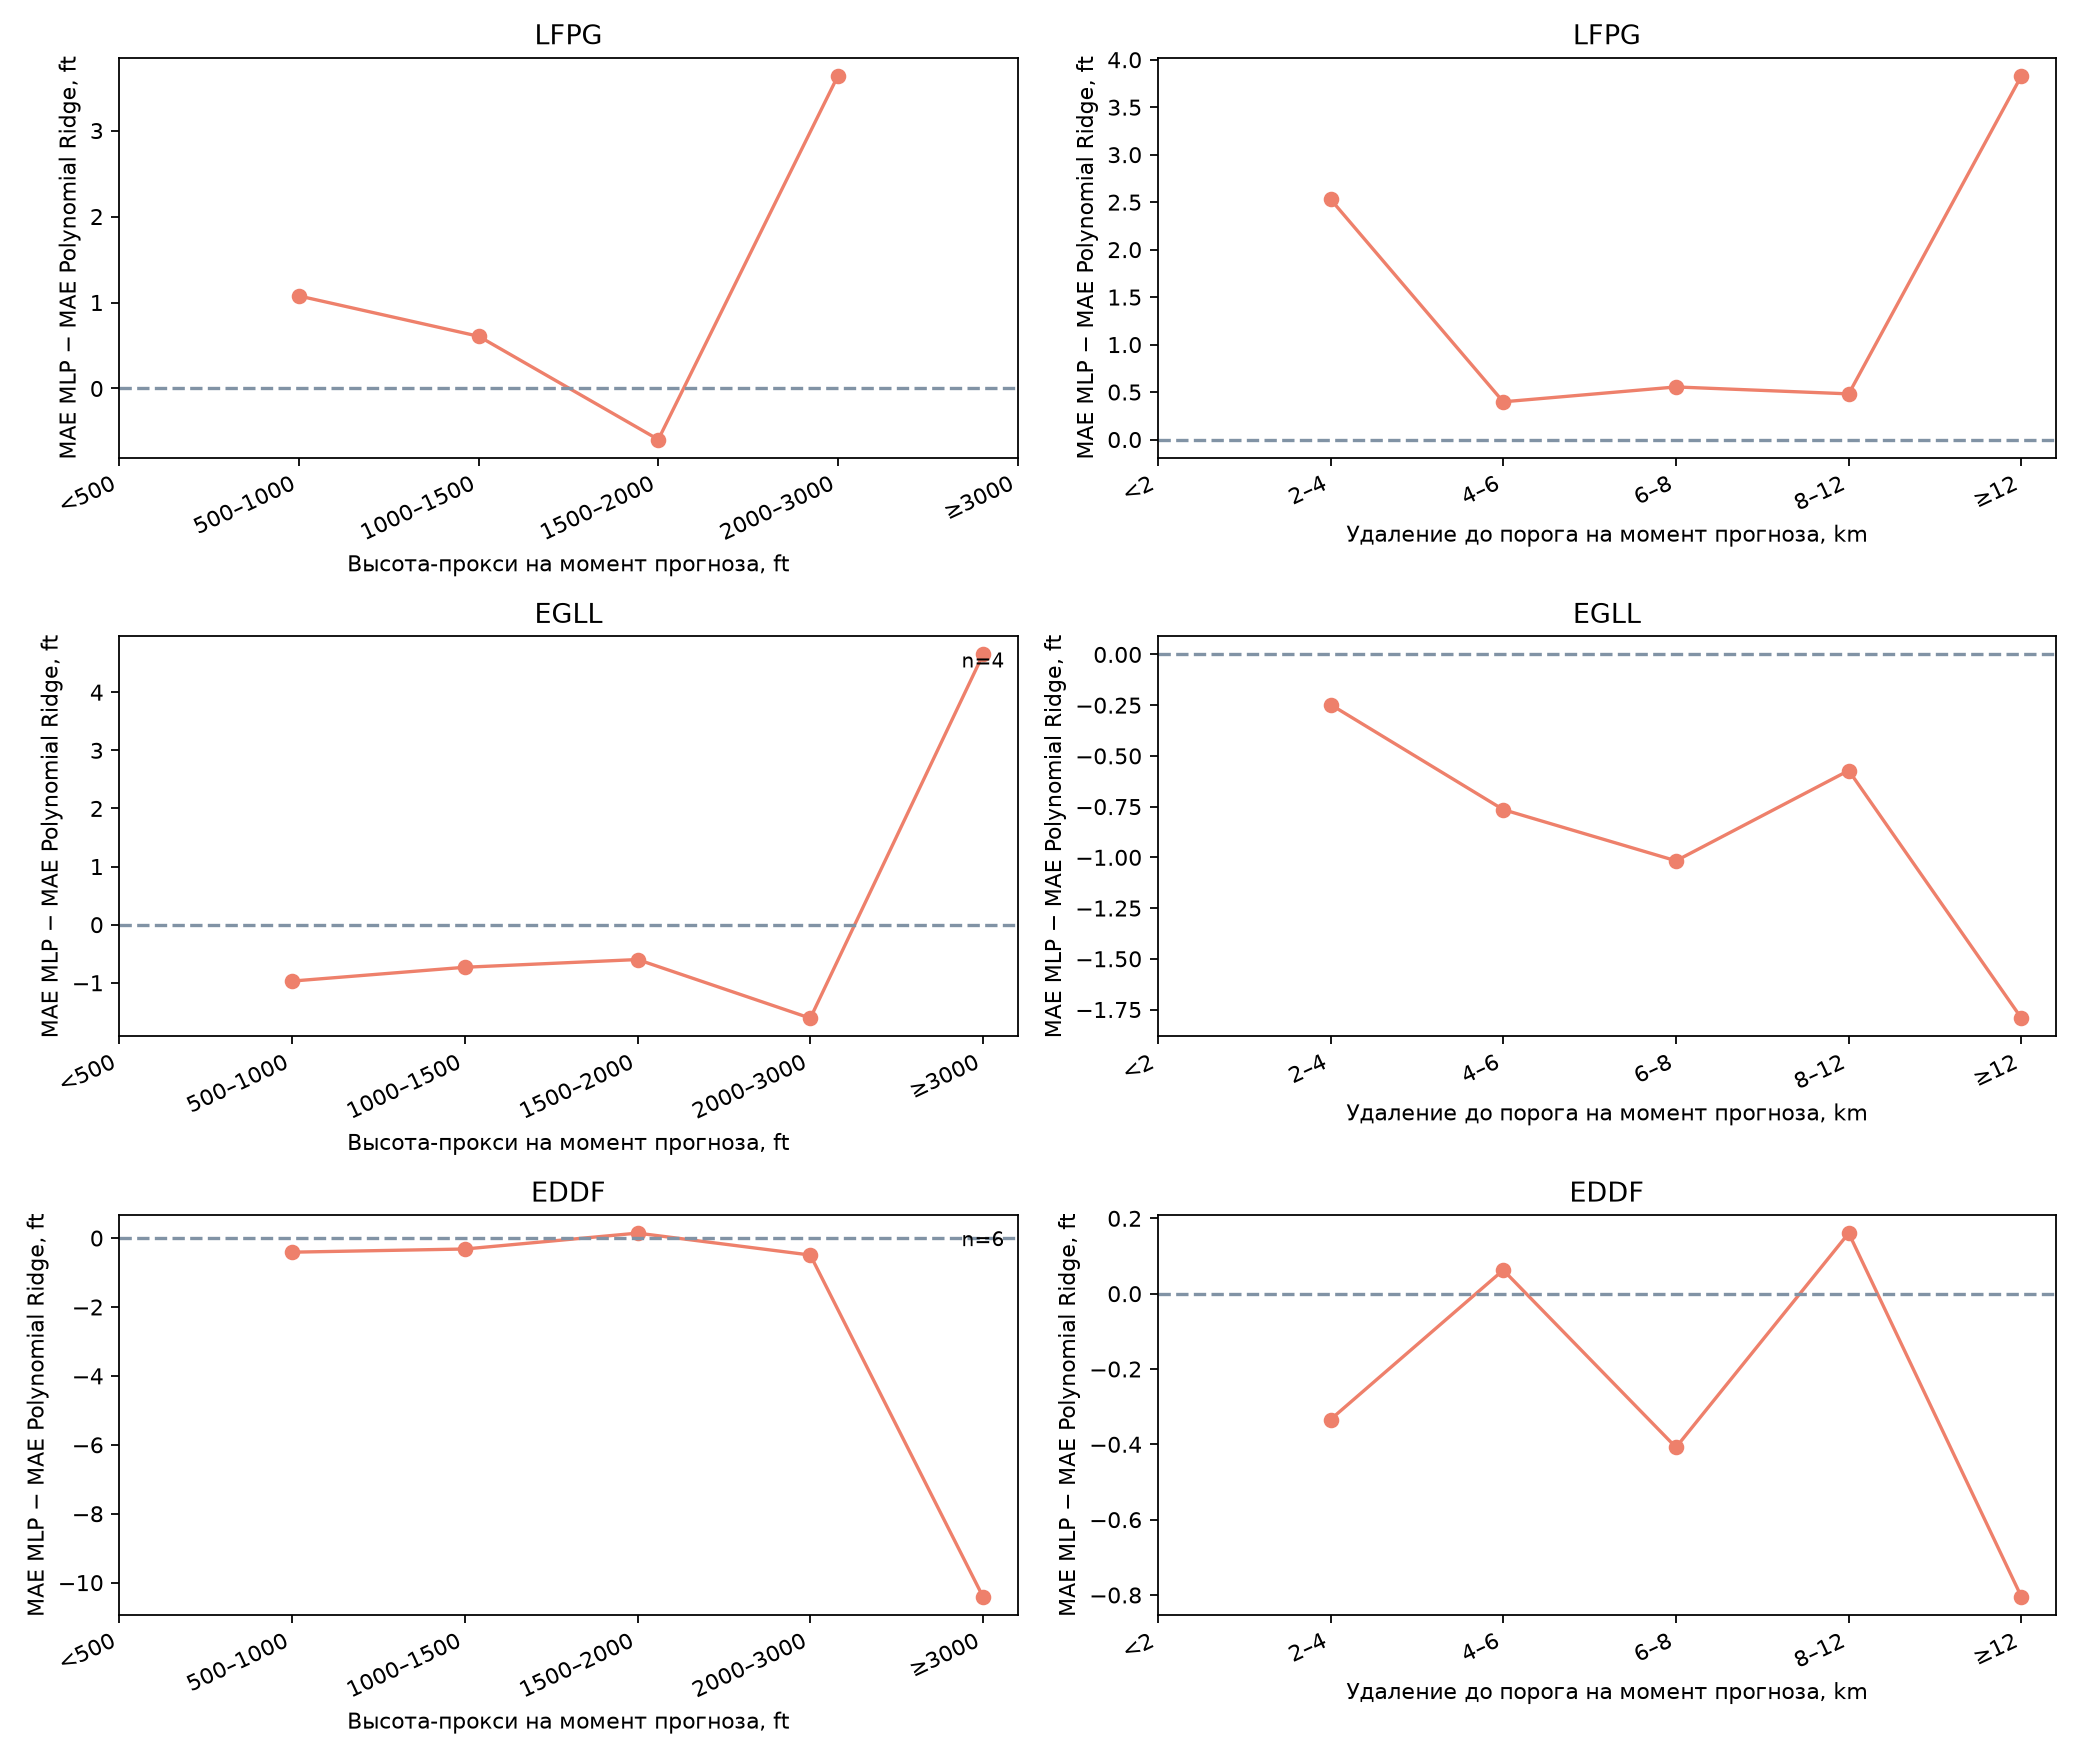

In [6]:
# Показываем ошибки, размеры групп и парные разницы фиксированных моделей
display(pd.read_csv(root / "reports/phase_errors.csv"))
display(pd.read_csv(root / "reports/phase_paired_errors.csv"))
display(Image(filename=str(root / "reports/phase_mae.png")))
display(Image(filename=str(root / "reports/phase_delta.png")))

В LFPG наибольший проигрыш MLP относительно Polynomial Ridge наблюдается в интервалах 2000–3000 ft и от 12 km. В EGLL средняя разница отрицательна во всех интервалах с большим числом заходов. В EDDF знак зависит от интервала. Группы от 3000 ft содержат лишь 4 захода EGLL и 6 EDDF; эти крайние значения не подтверждают устойчивую закономерность. Ниже 500 ft и ближе 2 km наблюдений нет. Интервалы неопределенности здесь не рассчитаны; анализ описательный, после просмотра test, без нового выбора параметров или признаков

## Ограничения сравнения

Размер и состав выборок различаются; абсолютная MAE не определяет сложность аэропорта. На сезон приходится один тестовый день, борта могут повторяться между split, фактический горизонт известен ретроспективно. Для MLP использован один seed. Парные интервалы оценены отдельно для каждого аэропорта и условны на наблюдаемых днях. Новые параметры по test не подбирались. Эксплуатационная применимость не установлена

## Совокупные исследовательские выводы

Обучаемая поправка уменьшает среднюю ошибку относительно продолжения вертикальной скорости во всех трех исследованных аэропортах. Универсального преимущества MLP над Polynomial Ridge не установлено: LFPG поддерживает Polynomial Ridge, EGLL поддерживает MLP на трех наблюдаемых днях, EDDF показывает смену знака разницы по дням. Эти выводы относятся к выбранным погожим дням и полосам

Следующая научная проверка должна заранее определить доступный на момент прогноза горизонт и независимые дни оценки. Текущие test-результаты не используются для нового подбора признаков или параметров. Go-around и эксплуатационная безопасность не оцениваются в этой работе

In [7]:
# Показываем проверку соответствия отчетов исходным MLflow runs
display(pd.read_csv(root / "reports/tracking_review.csv"))

,airport,model,run_id,metrics_match,git_commit_exists,dataset_hash_matches,artifact_root_entries
0,LFPG,Constant vertical rate,af81171321ba41da902589bff85a3858,True,True,True,3
1,LFPG,Ridge,58f9e5e9015e4478b4c9631b4aa613d0,True,True,True,4
2,LFPG,Polynomial Ridge,54224c6909c1451aa7c24c45feaa2dc5,True,True,True,4
3,LFPG,PyTorch MLP,e1e47564e32845768281b8f447e7e21b,True,True,True,5
4,EGLL,Constant vertical rate,77511f5022e34b5caf1c988466047793,True,True,True,3
5,EGLL,Ridge,019df70260ad45ec9299b2efc60829cc,True,True,True,4
6,EGLL,Polynomial Ridge,a1836409248444b0ae6250bd2a1aa52c,True,True,True,4
7,EGLL,PyTorch MLP,7432f453bb1e46e0924dc4ae5bfb212a,True,True,True,5
8,EDDF,Constant vertical rate,ab3f157c9a354866bb3673c2dd4f4138,True,True,True,3
9,EDDF,Ridge,586f82fc484d45c69e23761575b0b58b,True,True,True,4
